# TASK 2 – Unemployment Analysis with Python

## Objective

Perform Exploratory Data Analysis (EDA) on unemployment data in India to
identify regional and temporal trends and understand the impact of the
COVID-19 pandemic on unemployment rates.

## Tech Stack

- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Jupyter Notebook

## Dataset

The dataset used for this project is "Unemployment in India".

The dataset contains information about:
- Region
- Date
- Frequency
- Estimated Unemployment Rate (%)
- Estimated Employed
- Estimated Labour Participation Rate (%)
- Area

In [1]:
# Import required libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Display plots inside Jupyter Notebook
%matplotlib inline

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
# Load the unemployment dataset

df = pd.read_csv("Unemployment in India.csv")

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [3]:
# Display the first five rows

df.head()

,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area
0,Andhra Pradesh,31-05-2019,Monthly,3.65,11999139.0,43.24,Rural
1,Andhra Pradesh,30-06-2019,Monthly,3.05,11755881.0,42.05,Rural
2,Andhra Pradesh,31-07-2019,Monthly,3.75,12086707.0,43.50,Rural
3,Andhra Pradesh,31-08-2019,Monthly,3.32,12285693.0,43.97,Rural
4,Andhra Pradesh,30-09-2019,Monthly,5.17,12256762.0,44.68,Rural


In [4]:
# Check the number of rows and columns

print("Dataset Shape:", df.shape)

Dataset Shape: (768, 7)


In [5]:
# Display all column names

print("Column Names:")
print(df.columns.tolist())

Column Names:
['Region', ' Date', ' Frequency', ' Estimated Unemployment Rate (%)', ' Estimated Employed', ' Estimated Labour Participation Rate (%)', 'Area']


In [6]:
# Remove unnecessary spaces from column names

df.columns = df.columns.str.strip()

print(df.columns.tolist())

['Region', 'Date', 'Frequency', 'Estimated Unemployment Rate (%)', 'Estimated Employed', 'Estimated Labour Participation Rate (%)', 'Area']


In [7]:
# Check data types

print(df.dtypes)

Region                                         str
Date                                           str
Frequency                                      str
Estimated Unemployment Rate (%)            float64
Estimated Employed                         float64
Estimated Labour Participation Rate (%)    float64
Area                                           str
dtype: object


In [8]:
# Convert the Date column to datetime format

df["Date"] = pd.to_datetime(
    df["Date"],
    dayfirst=True,
    errors="coerce"
)

print(df["Date"].dtype)

datetime64[us]


In [9]:
# Check missing values in every column

print("Missing values:")
print(df.isnull().sum())

Missing values:
Region                                     28
Date                                       28
Frequency                                  28
Estimated Unemployment Rate (%)            28
Estimated Employed                         28
Estimated Labour Participation Rate (%)    28
Area                                       28
dtype: int64


In [10]:
# Calculate total missing values

print("\nTotal missing values:", df.isnull().sum().sum())


Total missing values: 196


In [11]:
# Clean whitespace from text columns

df["Region"] = df["Region"].str.strip()
df["Frequency"] = df["Frequency"].str.strip()
df["Area"] = df["Area"].str.strip()

print("Text columns cleaned successfully!")

Text columns cleaned successfully!


In [12]:
# Display dataset information

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 7 columns):
 #   Column                                   Non-Null Count  Dtype         
---  ------                                   --------------  -----         
 0   Region                                   740 non-null    str           
 1   Date                                     740 non-null    datetime64[us]
 2   Frequency                                740 non-null    str           
 3   Estimated Unemployment Rate (%)          740 non-null    float64       
 4   Estimated Employed                       740 non-null    float64       
 5   Estimated Labour Participation Rate (%)  740 non-null    float64       
 6   Area                                     740 non-null    str           
dtypes: datetime64[us](1), float64(3), str(3)
memory usage: 57.7 KB


In [13]:
# Display first five rows after cleaning

df.head()

,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area
0,Andhra Pradesh,2019-05-31,Monthly,3.65,11999139.0,43.24,Rural
1,Andhra Pradesh,2019-06-30,Monthly,3.05,11755881.0,42.05,Rural
2,Andhra Pradesh,2019-07-31,Monthly,3.75,12086707.0,43.50,Rural
3,Andhra Pradesh,2019-08-31,Monthly,3.32,12285693.0,43.97,Rural
4,Andhra Pradesh,2019-09-30,Monthly,5.17,12256762.0,44.68,Rural


# Exploratory Data Analysis

We will now examine unemployment rates, employment levels, and labour
participation across different regions and time periods.

In [14]:
# Display descriptive statistics for numerical columns

df.describe()

,Date,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%)
count,740,740.000000,7.400000e+02,740.000000
mean,2019-12-12 18:36:58.378378,11.787946,7.204460e+06,42.630122
min,2019-05-31 00:00:00,0.000000,4.942000e+04,13.330000
25%,2019-08-31 00:00:00,4.657500,1.190404e+06,38.062500
50%,2019-11-30 00:00:00,8.350000,4.744178e+06,41.160000
75%,2020-03-31 00:00:00,15.887500,1.127549e+07,45.505000
max,2020-06-30 00:00:00,76.740000,4.577751e+07,72.570000
std,NaN,10.721298,8.087988e+06,8.111094


## Region-wise Average Unemployment Rate

This analysis calculates the average unemployment rate for each region.
It helps identify which regions experienced relatively higher or lower
unemployment during the period covered by the dataset.

In [15]:
# Calculate average unemployment rate by region

region_avg_unemployment = (
    df.groupby("Region")["Estimated Unemployment Rate (%)"]
    .mean()
    .sort_values(ascending=False)
)

region_avg_unemployment

Region
Tripura             28.350357
Haryana             26.283214
Jharkhand           20.585000
Bihar               18.918214
Himachal Pradesh    18.540357
Delhi               16.495357
Jammu & Kashmir     16.188571
Chandigarh          15.991667
Rajasthan           14.058214
Uttar Pradesh       12.551429
Punjab              12.031071
Puducherry          10.215000
Kerala              10.123929
Tamil Nadu           9.284286
Goa                  9.274167
Chhattisgarh         9.240357
West Bengal          8.124643
Telangana            7.737857
Maharashtra          7.557500
Andhra Pradesh       7.477143
Madhya Pradesh       7.406429
Sikkim               7.249412
Karnataka            6.676071
Gujarat              6.663929
Uttarakhand          6.582963
Assam                6.428077
Odisha               5.657857
Meghalaya            4.798889
Name: Estimated Unemployment Rate (%), dtype: float64

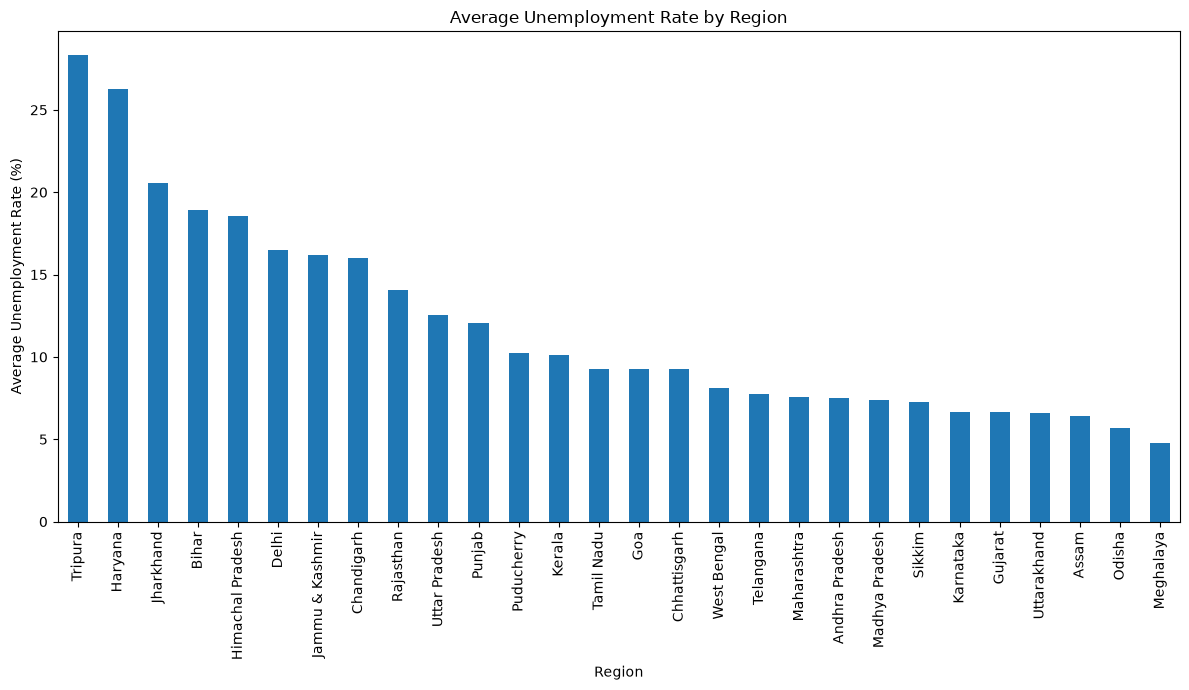

In [16]:
# Plot average unemployment rate by region

plt.figure(figsize=(12, 7))

region_avg_unemployment.plot(kind="bar")

plt.title("Average Unemployment Rate by Region")
plt.xlabel("Region")
plt.ylabel("Average Unemployment Rate (%)")
plt.xticks(rotation=90)

plt.tight_layout()
plt.show()

### Observation

The bar chart shows considerable variation in average unemployment rates
across different regions. Some regions experienced substantially higher
average unemployment than others during the period covered by the dataset.

This indicates that unemployment was not evenly distributed across India
and that regional economic conditions may have influenced unemployment levels.

## Month-wise Unemployment Trend

The dataset contains unemployment observations across different dates.
We will calculate the average unemployment rate for each month to identify
overall temporal patterns.

In [17]:
# Create a month column from the Date column

df["Month"] = df["Date"].dt.month

# Create month names
df["Month_Name"] = df["Date"].dt.month_name()

df[["Date", "Month", "Month_Name"]].head()


,Date,Month,Month_Name
0,2019-05-31,5.0,May
1,2019-06-30,6.0,June
2,2019-07-31,7.0,July
3,2019-08-31,8.0,August
4,2019-09-30,9.0,September


In [18]:
# Calculate average unemployment rate for each month

monthly_unemployment = (
    df.groupby(["Month", "Month_Name"])["Estimated Unemployment Rate (%)"]
    .mean()
    .reset_index()
    .sort_values("Month")
)

monthly_unemployment

,Month,Month_Name,Estimated Unemployment Rate (%)
0,1.0,January,9.950755
1,2.0,February,9.964717
2,3.0,March,10.700577
3,4.0,April,23.641569
4,5.0,May,16.646190
5,6.0,June,10.553462
6,7.0,July,9.033889
7,8.0,August,9.637925
8,9.0,September,9.051731
9,10.0,October,9.900909


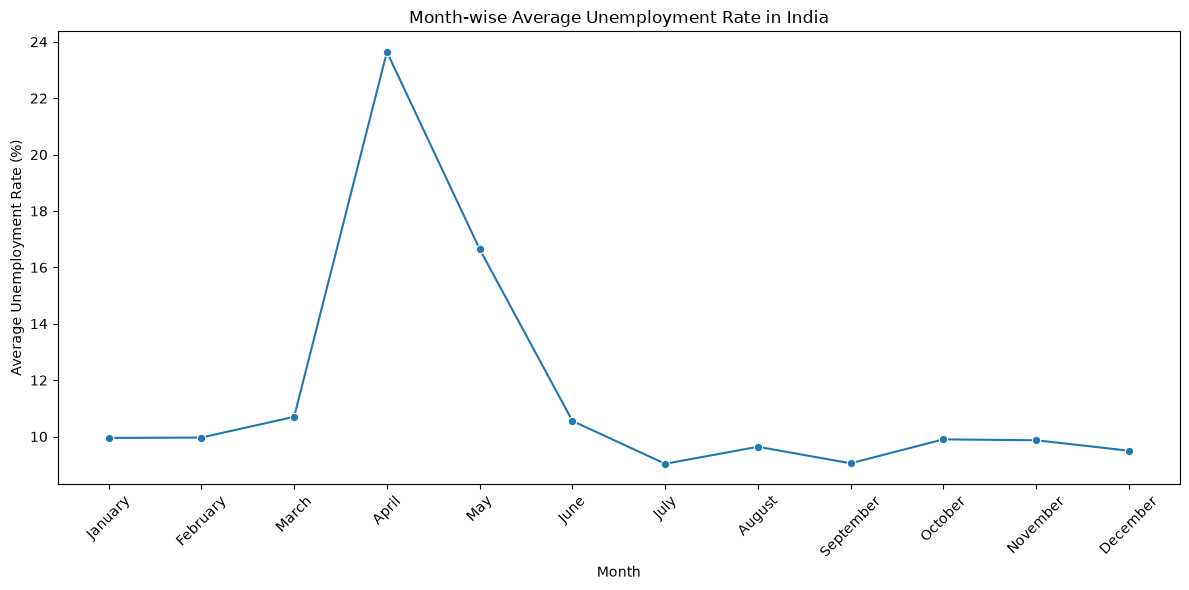

In [19]:
# Plot month-wise average unemployment rate

plt.figure(figsize=(12, 6))

sns.lineplot(
    data=monthly_unemployment,
    x="Month_Name",
    y="Estimated Unemployment Rate (%)",
    marker="o"
)

plt.title("Month-wise Average Unemployment Rate in India")
plt.xlabel("Month")
plt.ylabel("Average Unemployment Rate (%)")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

### Observation

The month-wise trend shows that unemployment rates varied across the year.
The variation indicates that unemployment was influenced by seasonal and
economic factors during the period covered by the dataset.

## Overall Unemployment Trend Over Time

A time-series chart helps us understand how India's unemployment rate
changed throughout the period covered by the dataset.

In [21]:
# Calculate average unemployment rate for each date

daily_unemployment = (
    df.groupby("Date")["Estimated Unemployment Rate (%)"]
    .mean()
    .reset_index()
    .sort_values("Date")
)

daily_unemployment.head()

,Date,Estimated Unemployment Rate (%)
0,2019-05-31,8.874259
1,2019-06-30,9.303333
2,2019-07-31,9.033889
3,2019-08-31,9.637925
4,2019-09-30,9.051731


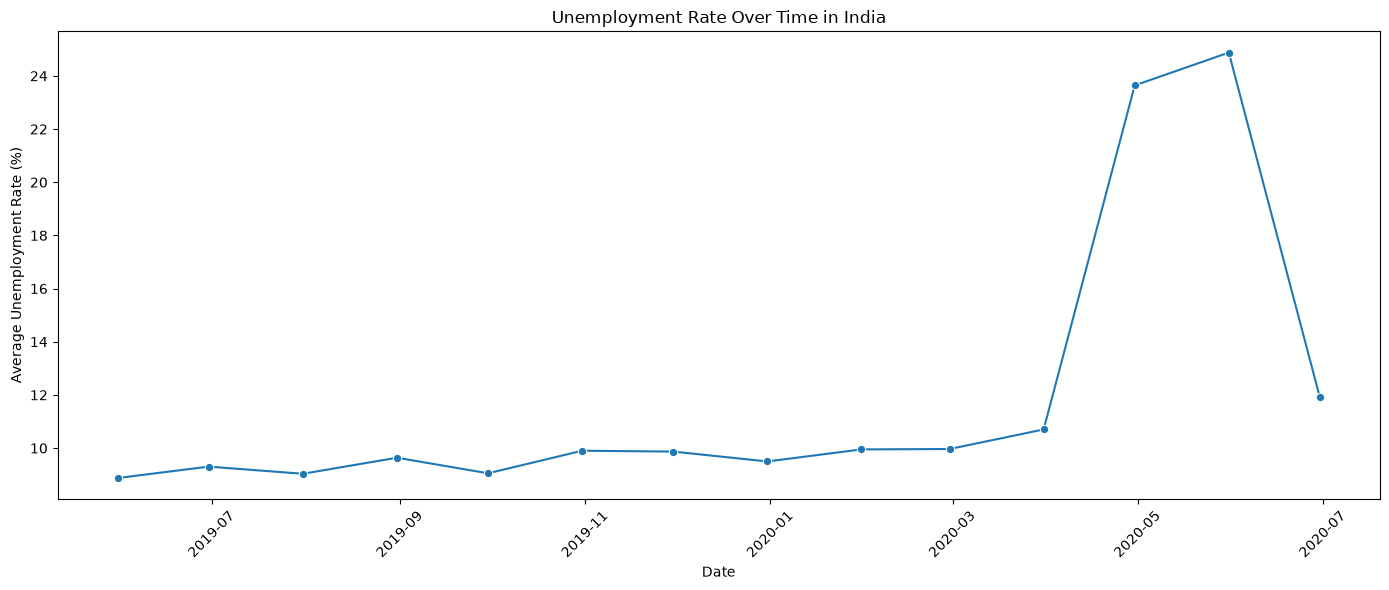

In [22]:
# Plot overall unemployment trend

plt.figure(figsize=(14, 6))

sns.lineplot(
    data=daily_unemployment,
    x="Date",
    y="Estimated Unemployment Rate (%)",
    marker="o"
)

plt.title("Unemployment Rate Over Time in India")
plt.xlabel("Date")
plt.ylabel("Average Unemployment Rate (%)")

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

### Observation

The time-series chart shows fluctuations in unemployment over the study
period. A noticeable increase can be observed around the period associated
with the COVID-19 pandemic, indicating a major disruption in employment
conditions.

## COVID-19 Period

The COVID-19 pandemic caused major economic disruption in India during 2020.
We will compare unemployment levels before and during the pandemic period
using the available data.

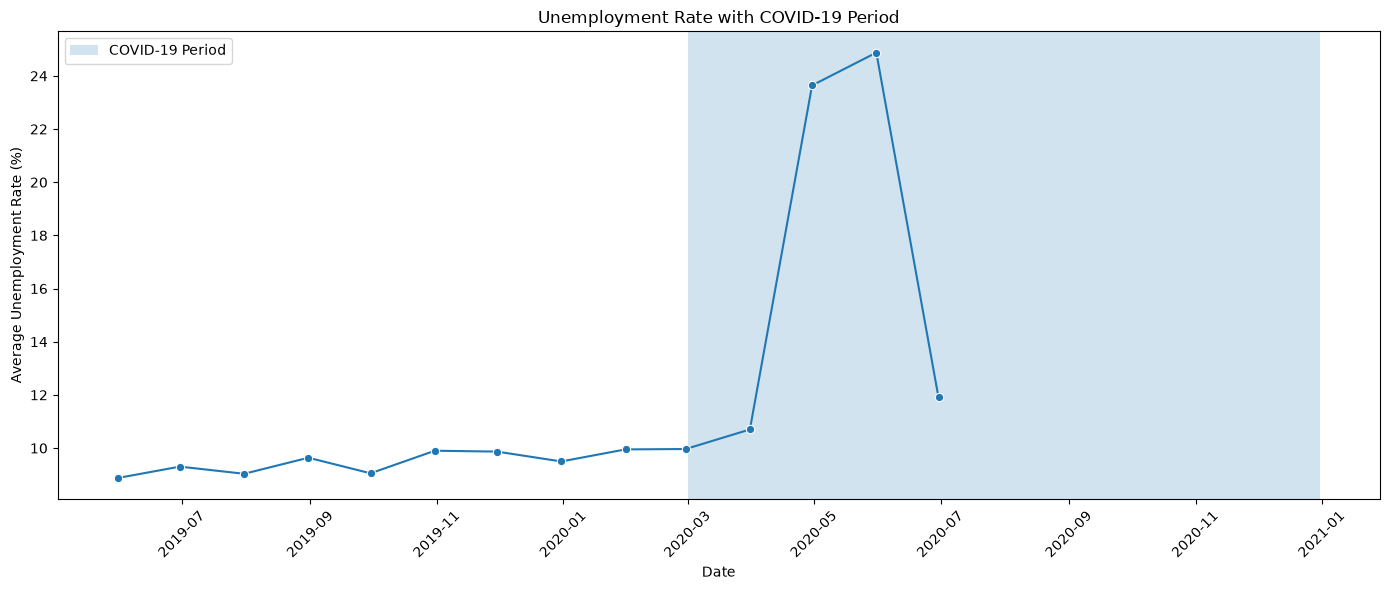

In [24]:
# Plot unemployment trend with COVID-19 period highlighted

plt.figure(figsize=(14, 6))

sns.lineplot(
    data=daily_unemployment,
    x="Date",
    y="Estimated Unemployment Rate (%)",
    marker="o"
)

# Highlight COVID period
plt.axvspan(
    pd.Timestamp("2020-03-01"),
    pd.Timestamp("2020-12-31"),
    alpha=0.2,
    label="COVID-19 Period"
)

plt.title("Unemployment Rate with COVID-19 Period")
plt.xlabel("Date")
plt.ylabel("Average Unemployment Rate (%)")

plt.legend()
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

### Observation

The highlighted COVID-19 period allows us to visually compare unemployment
before and during the pandemic. The unemployment rate shows a sharp disruption
around the beginning of the pandemic, reflecting the impact of lockdowns and
economic activity restrictions.

In [25]:
# Display all regions in the dataset

print(df["Region"].unique())

<ArrowStringArray>
[  'Andhra Pradesh',            'Assam',            'Bihar',
     'Chhattisgarh',            'Delhi',              'Goa',
          'Gujarat',          'Haryana', 'Himachal Pradesh',
  'Jammu & Kashmir',        'Jharkhand',        'Karnataka',
           'Kerala',   'Madhya Pradesh',      'Maharashtra',
        'Meghalaya',           'Odisha',       'Puducherry',
           'Punjab',        'Rajasthan',           'Sikkim',
       'Tamil Nadu',        'Telangana',          'Tripura',
    'Uttar Pradesh',      'Uttarakhand',      'West Bengal',
                nan,       'Chandigarh']
Length: 29, dtype: str


## State-wise Unemployment Trends

We will compare unemployment trends for three major regions:
Maharashtra, Delhi, and West Bengal.

In [26]:
# Select three major regions

selected_regions = [
    "Maharashtra",
    "Delhi",
    "West Bengal"
]

region_trend = (
    df[df["Region"].isin(selected_regions)]
    .groupby(["Date", "Region"])["Estimated Unemployment Rate (%)"]
    .mean()
    .reset_index()
    .sort_values("Date")
)

region_trend.head()

,Date,Region,Estimated Unemployment Rate (%)
0,2019-05-31,Delhi,12.435
1,2019-05-31,Maharashtra,4.875
2,2019-05-31,West Bengal,6.635
3,2019-06-30,Delhi,11.045
4,2019-06-30,Maharashtra,5.400


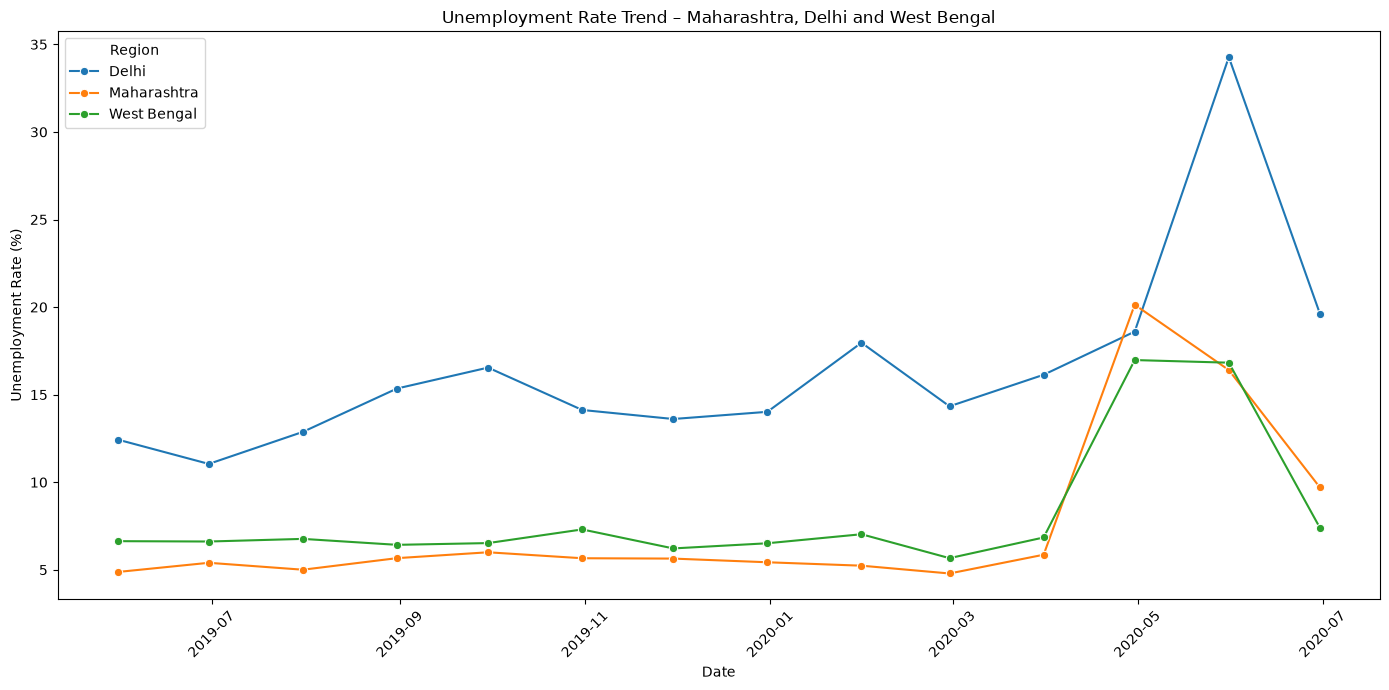

In [27]:
# Plot unemployment trends for three regions

plt.figure(figsize=(14, 7))

sns.lineplot(
    data=region_trend,
    x="Date",
    y="Estimated Unemployment Rate (%)",
    hue="Region",
    marker="o"
)

plt.title("Unemployment Rate Trend – Maharashtra, Delhi and West Bengal")
plt.xlabel("Date")
plt.ylabel("Unemployment Rate (%)")

plt.xticks(rotation=45)
plt.legend(title="Region")

plt.tight_layout()
plt.show()

### Observation

The three regions show different unemployment patterns over time.
Although all regions were affected by economic disruptions, the magnitude
and timing of changes were not identical.

The comparison demonstrates that the impact of unemployment varied
considerably across regions.


## Top 10 Regions with Highest Average Unemployment Rate

This analysis identifies the ten regions with the highest average
unemployment rate during the period covered by the dataset.

In [29]:
# Calculate the top 10 regions with the highest average unemployment rate

top_10_regions = (
    df.groupby("Region")["Estimated Unemployment Rate (%)"]
    .mean()
    .sort_values(ascending=False)
    .head(10)
)

print("Top 10 Regions with Highest Average Unemployment Rate:")
print(top_10_regions)

Top 10 Regions with Highest Average Unemployment Rate:
Region
Tripura             28.350357
Haryana             26.283214
Jharkhand           20.585000
Bihar               18.918214
Himachal Pradesh    18.540357
Delhi               16.495357
Jammu & Kashmir     16.188571
Chandigarh          15.991667
Rajasthan           14.058214
Uttar Pradesh       12.551429
Name: Estimated Unemployment Rate (%), dtype: float64


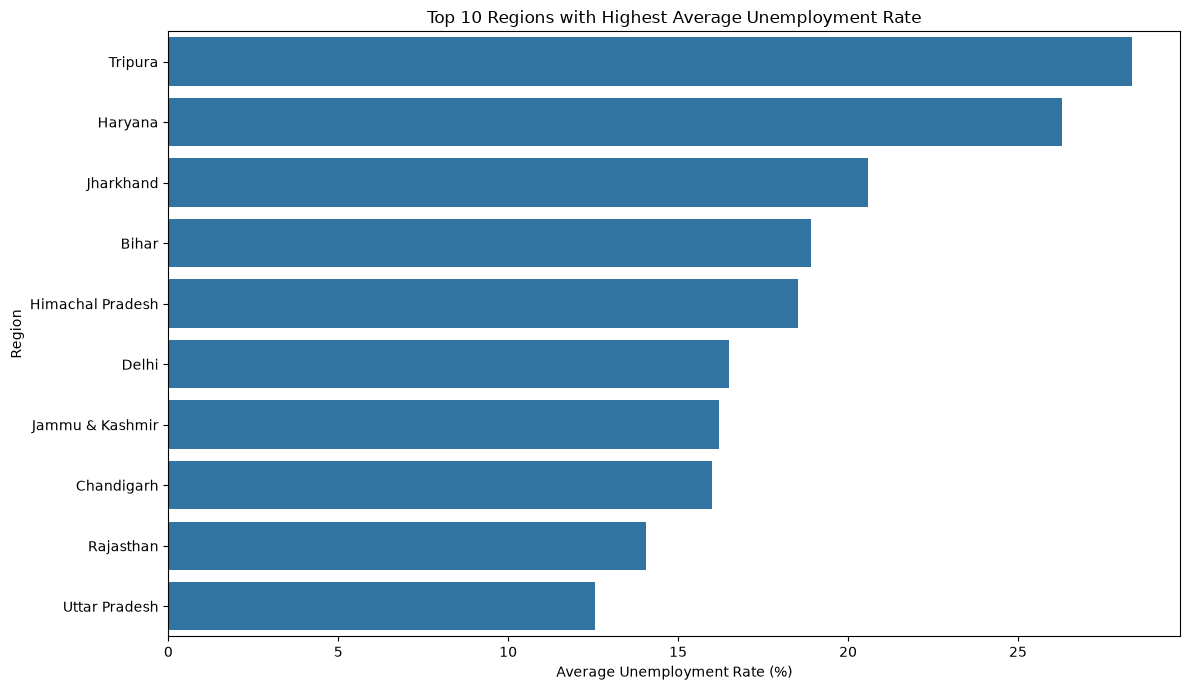

In [30]:
# Plot top 10 regions with highest average unemployment

plt.figure(figsize=(12, 7))

sns.barplot(
    x=top_10_regions.values,
    y=top_10_regions.index
)

plt.title("Top 10 Regions with Highest Average Unemployment Rate")
plt.xlabel("Average Unemployment Rate (%)")
plt.ylabel("Region")

plt.tight_layout()
plt.show()

### Observation

The top 10 chart highlights the regions with the highest average
unemployment rates. These regions experienced comparatively greater
unemployment during the period analyzed.

The ranking also demonstrates the substantial regional variation present
in India's unemployment data.

## Correlation Analysis

Correlation analysis helps us understand the strength and direction of
relationships between unemployment rate, employment level, and labour
participation rate.

A heatmap will be used to visualize these correlations.

In [31]:
# Select numerical variables for correlation analysis

correlation_data = df[
    [
        "Estimated Unemployment Rate (%)",
        "Estimated Employed",
        "Estimated Labour Participation Rate (%)"
    ]
]

# Calculate correlation matrix
correlation_matrix = correlation_data.corr()

correlation_matrix

,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%)
Estimated Unemployment Rate (%),1.000000,-0.222876,0.002558
Estimated Employed,-0.222876,1.000000,0.011300
Estimated Labour Participation Rate (%),0.002558,0.011300,1.000000


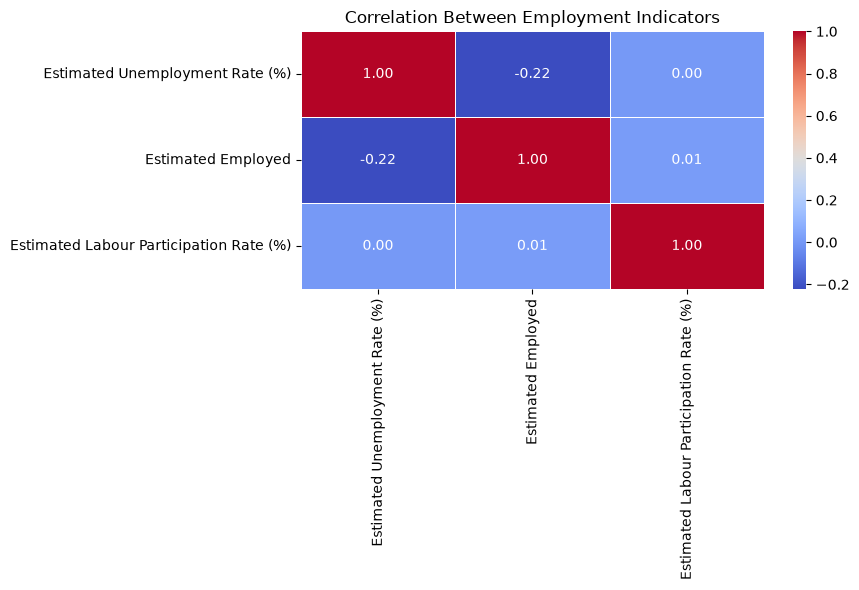

In [32]:
# Plot correlation heatmap

plt.figure(figsize=(9, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Between Employment Indicators")

plt.tight_layout()
plt.show()

### Observation

The correlation heatmap shows the relationships between unemployment rate,
employment level, and labour participation rate.

A positive correlation means that two variables tend to increase together,
while a negative correlation means that one tends to decrease when the other
increases.

Correlation indicates association and should not be interpreted as proof
of a causal relationship.

## Pre-COVID vs COVID/Post-COVID Comparison

To understand the impact of the COVID-19 pandemic, the dataset is divided
into two periods:

- Pre-COVID: before March 2020
- COVID/Post-COVID: March 2020 onward

We will compare average unemployment, employment, and labour participation
rates between the two periods.

In [34]:
# Create COVID period classification

df["Period"] = np.where(
    df["Date"] < pd.Timestamp("2020-03-01"),
    "Pre-COVID",
    "COVID/Post-COVID"
)

# Check number of observations in each period

print(df["Period"].value_counts())

Period
Pre-COVID           536
COVID/Post-COVID    232
Name: count, dtype: int64


In [35]:
# Calculate mean values for each period

period_comparison = (
    df.groupby("Period")[
        [
            "Estimated Unemployment Rate (%)",
            "Estimated Employed",
            "Estimated Labour Participation Rate (%)"
        ]
    ]
    .mean()
)

period_comparison

,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%)
Period,,,
COVID/Post-COVID,17.774363,6.517203e+06,39.330049
Pre-COVID,9.509534,7.466028e+06,43.886119


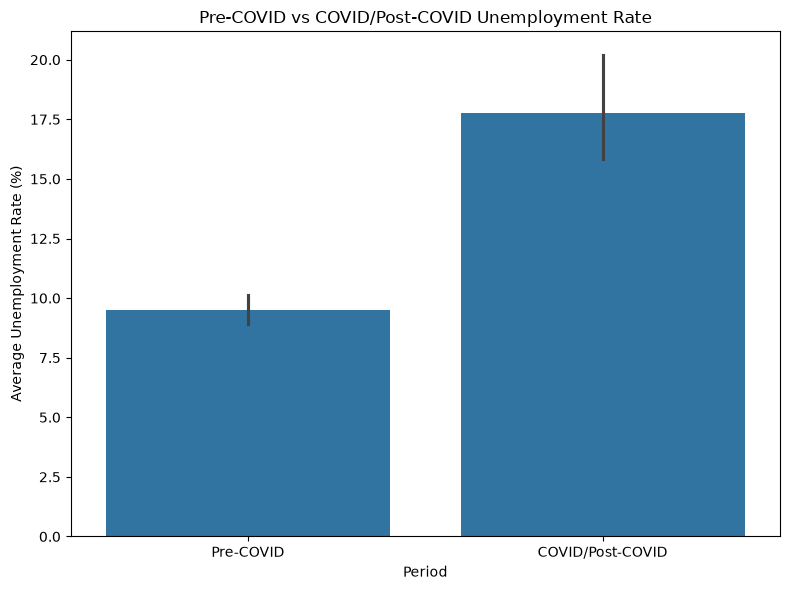

In [36]:
# Compare unemployment rate between the two periods

plt.figure(figsize=(8, 6))

sns.barplot(
    data=df,
    x="Period",
    y="Estimated Unemployment Rate (%)"
)

plt.title("Pre-COVID vs COVID/Post-COVID Unemployment Rate")
plt.xlabel("Period")
plt.ylabel("Average Unemployment Rate (%)")

plt.tight_layout()
plt.show()